# Artificial Neural Network for California Housing Price Prediction

## 1. Introduction

Artificial Neural Networks (ANNs) are machine learning models inspired by biological neural networks.

This project uses an ANN to predict median house values using the California Housing dataset.

## 2. Objectives

1. Develop an ANN for housing price prediction.
2. Investigate the effect of different numbers of hidden layers.
3. Compare different activation functions.
4. Examine the influence of different learning rates.
5. Evaluate model performance using R², MAE, and RMSE.
6. Identify the best-performing ANN configuration.

## 3. Dataset

- Dataset: California Housing
- Problem type: Regression
- Target variable: median_house_value

## 4. Experimental Design

- Hidden layers: 2 to 10
- Activation functions: To be selected
- Learning rates: 0.0001, 0.001, 0.01
- Evaluation metrics: R², MAE, RMSE

In [2]:
# Importing required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import time

# Importing machine learning tools
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline

from sklearn.neural_network import MLPRegressor

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [3]:
# Loading the California Housing dataset

df = pd.read_csv("../data/housing.csv")

# Display the first five rows
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
# Display the number of rows and columns

print("Dataset shape:", df.shape)

# Display the number of rows
print("Number of records:", df.shape[0])

# Display the number of columns
print("Number of features and target columns:", df.shape[1])

Dataset shape: (20640, 10)
Number of records: 20640
Number of features and target columns: 10


In [5]:
# Display information about the dataset

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.7 MB


In [6]:
# Count missing values in each column

missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


In [7]:
# Display unique categories in ocean_proximity

print("Unique ocean proximity categories:")
print(df["ocean_proximity"].unique())

# Count records in each category
print("\nCategory frequencies:")
print(df["ocean_proximity"].value_counts())

Unique ocean proximity categories:
<ArrowStringArray>
['NEAR BAY', '<1H OCEAN', 'INLAND', 'NEAR OCEAN', 'ISLAND']
Length: 5, dtype: str

Category frequencies:
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


In [8]:
# Separate input features (X) and target variable (y)

X = df.drop("median_house_value", axis=1)

y = df["median_house_value"]

# Display their shapes

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

# Display the first five input records
display(X.head())

# Display the first five target values
display(y.head())

Input features shape: (20640, 9)
Target variable shape: (20640,)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,NEAR BAY


0    452600.0
1    358500.0
2    352100.0
3    341300.0
4    342200.0
Name: median_house_value, dtype: float64

In [9]:
print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

Input features shape: (20640, 9)
Target variable shape: (20640,)


In [10]:
# Splitting the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Display the shapes

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training input shape: (16512, 9)
Testing input shape: (4128, 9)
Training target shape: (16512,)
Testing target shape: (4128,)


In [11]:
# Select numerical input columns

numerical_columns = X_train.select_dtypes(
    include=["number"]
).columns

# Display descriptive statistics

print("Numerical feature statistics:")
display(X_train[numerical_columns].describe())

Numerical feature statistics:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
count,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000
mean,-119.582290,35.643149,28.608285,2642.004784,538.496851,1426.453004,499.986919,3.880754
std,2.005654,2.136665,12.602499,2174.646744,419.007096,1137.056380,380.967964,1.904294
min,-124.350000,32.550000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900
25%,-121.810000,33.930000,18.000000,1454.000000,296.750000,789.000000,280.000000,2.566700
50%,-118.510000,34.260000,29.000000,2129.000000,437.000000,1167.000000,410.000000,3.545800
75%,-118.010000,37.720000,37.000000,3160.000000,647.000000,1726.000000,606.000000,4.773175
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100


In [12]:
# Create a StandardScaler object

scaler = StandardScaler()

# Fit the scaler using training data
scaler.fit(X_train[numerical_columns])

# Transform training numerical features
X_train_scaled = scaler.transform(
    X_train[numerical_columns]
)

# Display the scaled data
print("First five standardized records:")

display(pd.DataFrame(
    X_train_scaled,
    columns=numerical_columns
).head())

First five standardized records:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
0,1.272587,-1.372811,0.348490,0.222569,0.211228,0.768276,0.322906,-0.326196
1,0.709162,-0.876696,1.618118,0.340293,0.593094,-0.098901,0.672027,-0.035843
2,-0.447603,-0.460146,-1.952710,-0.342597,-0.495226,-0.449818,-0.430461,0.144701
3,1.232698,-1.382172,0.586545,-0.561490,-0.409306,-0.007434,-0.380587,-1.017864
4,-0.108551,0.532084,1.142008,-0.119565,-0.256559,-0.485877,-0.314962,-0.171488


In [13]:
# Identify numerical and categorical input columns

numerical_columns = X_train.select_dtypes(
    include=["number"]
).columns

categorical_columns = X_train.select_dtypes(
    exclude=["number"]
).columns

print("Numerical columns:")
print(list(numerical_columns))

print("\nCategorical columns:")
print(list(categorical_columns))

Numerical columns:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']

Categorical columns:
['ocean_proximity']


In [14]:
# Preprocessing pipeline for numerical features

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [15]:
# Combine numerical and categorical preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_columns),
        ("cat", categorical_transformer, categorical_columns)
    ]
)

NameError: name 'categorical_transformer' is not defined

In [16]:
# Re-create categorical preprocessing pipeline

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

print("Categorical preprocessing pipeline created successfully.")

Categorical preprocessing pipeline created successfully.


In [17]:
# Combine numerical and categorical preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_columns),
        ("cat", categorical_transformer, categorical_columns)
    ]
)

print("Complete preprocessing system created successfully.")

Complete preprocessing system created successfully.


In [18]:
# Apply preprocessing to training data

X_train_processed = preprocessor.fit_transform(X_train)

print("Original training data shape:", X_train.shape)
print("Processed training data shape:", X_train_processed.shape)

Original training data shape: (16512, 9)
Processed training data shape: (16512, 13)


In [19]:
# Display the names of processed features

feature_names = preprocessor.get_feature_names_out()

print("Processed feature names:")
print(feature_names)

print("\nTotal number of processed features:", len(feature_names))

Processed feature names:
['num__longitude' 'num__latitude' 'num__housing_median_age'
 'num__total_rooms' 'num__total_bedrooms' 'num__population'
 'num__households' 'num__median_income' 'cat__ocean_proximity_<1H OCEAN'
 'cat__ocean_proximity_INLAND' 'cat__ocean_proximity_ISLAND'
 'cat__ocean_proximity_NEAR BAY' 'cat__ocean_proximity_NEAR OCEAN']

Total number of processed features: 13


In [20]:
# Transform testing data using the fitted preprocessor

X_test_processed = preprocessor.transform(X_test)

print("Original testing data shape:", X_test.shape)
print("Processed testing data shape:", X_test_processed.shape)

Original testing data shape: (4128, 9)
Processed testing data shape: (4128, 13)


In [21]:
# Examine the target variable

print("Training target statistics:")
display(y_train.describe())

print("\nTesting target statistics:")
display(y_test.describe())

Training target statistics:


count     16512.000000
mean     207194.693738
std      115622.626448
min       14999.000000
25%      119800.000000
50%      179850.000000
75%      265125.000000
max      500001.000000
Name: median_house_value, dtype: float64


Testing target statistics:


count      4128.000000
mean     205500.309593
std      114486.964288
min       14999.000000
25%      119275.000000
50%      178650.000000
75%      263000.000000
max      500001.000000
Name: median_house_value, dtype: float64

In [22]:
# Create a scaler for the target variable

target_scaler = StandardScaler()

print("Target scaler created successfully.")

Target scaler created successfully.


In [23]:
# Fit target scaler using training target values

y_train_scaled = target_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
)

print("Original target values:")
print(y_train.head().values)

print("\nScaled target values:")
print(y_train_scaled[:5].flatten())

Original target values:
[103000. 382100. 172600.  93400.  96500.]

Scaled target values:
[-0.90118909  1.5127714  -0.29921255 -0.98422033 -0.95740816]


In [25]:
# Define activation functions for ANN experiments

activation_functions = [
    "relu",
    "logistic",
    "tanh"
]

print("Activation functions selected:")
for activation in activation_functions:
    print(activation)

Activation functions selected:
relu
logistic
tanh


In [26]:
# Define hidden-layer configurations

hidden_layer_configurations = [
    (32, 32),
    (32, 32, 32),
    (32, 32, 32, 32),
    (32, 32, 32, 32, 32),
    (32, 32, 32, 32, 32, 32),
    (32, 32, 32, 32, 32, 32, 32),
    (32, 32, 32, 32, 32, 32, 32, 32),
    (32, 32, 32, 32, 32, 32, 32, 32, 32),
    (32, 32, 32, 32, 32, 32, 32, 32, 32, 32)
]

print("Total hidden-layer configurations:", len(hidden_layer_configurations))

for i, configuration in enumerate(hidden_layer_configurations, start=1):
    print(f"Experiment {i}: {len(configuration)} hidden layers")

Total hidden-layer configurations: 9
Experiment 1: 2 hidden layers
Experiment 2: 3 hidden layers
Experiment 3: 4 hidden layers
Experiment 4: 5 hidden layers
Experiment 5: 6 hidden layers
Experiment 6: 7 hidden layers
Experiment 7: 8 hidden layers
Experiment 8: 9 hidden layers
Experiment 9: 10 hidden layers


In [27]:
# Define learning rates for ANN experiments

learning_rates = [
    0.0001,
    0.001,
    0.01
]

print("Learning rates selected:")

for rate in learning_rates:
    print(rate)

Learning rates selected:
0.0001
0.001
0.01


In [28]:
# Calculate total ANN experiments

total_experiments = (
    len(hidden_layer_configurations)
    * len(activation_functions)
    * len(learning_rates)
)

print("Total ANN experiments:", total_experiments)

Total ANN experiments: 81


In [30]:
# Create the first ANN model

ann_model = MLPRegressor(
    hidden_layer_sizes=(32, 32),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=200,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=15,
    random_state=42
)

print(ann_model)

MLPRegressor(early_stopping=True, hidden_layer_sizes=(32, 32),
             n_iter_no_change=15, random_state=42)


In [31]:
# Wrap the ANN model with target scaling

ann_model_scaled = TransformedTargetRegressor(
    regressor=ann_model,
    transformer=StandardScaler()
)

print("ANN model with target scaling created successfully.")

ANN model with target scaling created successfully.


In [33]:
# Train the first ANN model

start_time = time.time()

ann_model_scaled.fit(
    X_train_processed,
    y_train
)

training_time = time.time() - start_time

print("ANN training completed successfully!")
print("Training time:", round(training_time, 2), "seconds")
print("Iterations completed:", ann_model_scaled.regressor_.n_iter_)

ANN training completed successfully!
Training time: 4.58 seconds
Iterations completed: 91


In [34]:
# Generate predictions using the trained ANN

y_pred = ann_model_scaled.predict(X_test_processed)

print("First 10 actual house values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted house values:")
print(y_pred[:10])

First 10 actual house values:
[ 47700.  45800. 500001. 218600. 278000. 158700. 198200. 157500. 340000.
 446600.]

First 10 predicted house values:
[ 41132.59276834  77200.37121793 420031.30223841 256057.352066
 270730.96519768 155506.82887393 357712.01072793 199067.63356051
 250680.62872805 455145.15705251]


In [35]:
# Evaluate the first ANN model

r2 = r2_score(y_test, y_pred)

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("ANN Model Performance")
print("----------------------")
print("R2 Score:", round(r2, 4))
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

ANN Model Performance
----------------------
R2 Score: 0.7707
MAE: 37653.92
RMSE: 54818.84


In [36]:
# Create an empty list to store ANN experiment results

ann_results = []

print("ANN results storage created successfully.")
print("Initial number of results:", len(ann_results))

ANN results storage created successfully.
Initial number of results: 0


In [37]:
experiment_number = 0

for hidden_layers in hidden_layer_configurations:

    for activation in activation_functions:

        for learning_rate in learning_rates:

            experiment_number += 1

            print(
                f"Experiment {experiment_number}/{total_experiments}"
            )

            print("Hidden layers:", len(hidden_layers))
            print("Activation function:", activation)
            print("Learning rate:", learning_rate)

            print("-----------------------------")

Experiment 1/81
Hidden layers: 2
Activation function: relu
Learning rate: 0.0001
-----------------------------
Experiment 2/81
Hidden layers: 2
Activation function: relu
Learning rate: 0.001
-----------------------------
Experiment 3/81
Hidden layers: 2
Activation function: relu
Learning rate: 0.01
-----------------------------
Experiment 4/81
Hidden layers: 2
Activation function: logistic
Learning rate: 0.0001
-----------------------------
Experiment 5/81
Hidden layers: 2
Activation function: logistic
Learning rate: 0.001
-----------------------------
Experiment 6/81
Hidden layers: 2
Activation function: logistic
Learning rate: 0.01
-----------------------------
Experiment 7/81
Hidden layers: 2
Activation function: tanh
Learning rate: 0.0001
-----------------------------
Experiment 8/81
Hidden layers: 2
Activation function: tanh
Learning rate: 0.001
-----------------------------
Experiment 9/81
Hidden layers: 2
Activation function: tanh
Learning rate: 0.01
----------------------------

In [38]:
ann_model = MLPRegressor(
    hidden_layer_sizes=(32, 32),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=200,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=15,
    random_state=42
)

In [40]:
# Test creating ANN models for all combinations

experiment_number = 0

for hidden_layers in hidden_layer_configurations:

    for activation in activation_functions:

        for learning_rate in learning_rates:

            experiment_number += 1

            ann_model = MLPRegressor(
                hidden_layer_sizes=hidden_layers,
                activation=activation,
                solver="adam",
                learning_rate_init=learning_rate,
                max_iter=200,
                early_stopping=True,
                validation_fraction=0.1,
                n_iter_no_change=15,
                random_state=42
            )

            print(f"Experiment {experiment_number}/81")
            print(ann_model)
            print("-----------------------------")

Experiment 1/81
MLPRegressor(early_stopping=True, hidden_layer_sizes=(32, 32),
             learning_rate_init=0.0001, n_iter_no_change=15, random_state=42)
-----------------------------
Experiment 2/81
MLPRegressor(early_stopping=True, hidden_layer_sizes=(32, 32),
             n_iter_no_change=15, random_state=42)
-----------------------------
Experiment 3/81
MLPRegressor(early_stopping=True, hidden_layer_sizes=(32, 32),
             learning_rate_init=0.01, n_iter_no_change=15, random_state=42)
-----------------------------
Experiment 4/81
MLPRegressor(activation='logistic', early_stopping=True,
             hidden_layer_sizes=(32, 32), learning_rate_init=0.0001,
             n_iter_no_change=15, random_state=42)
-----------------------------
Experiment 5/81
MLPRegressor(activation='logistic', early_stopping=True,
             hidden_layer_sizes=(32, 32), n_iter_no_change=15, random_state=42)
-----------------------------
Experiment 6/81
MLPRegressor(activation='logistic', early_stop

In [41]:
# Create one ANN model

test_mlp = MLPRegressor(
    hidden_layer_sizes=(32, 32),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=200,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=15,
    random_state=42
)

# Apply target scaling

test_model = TransformedTargetRegressor(
    regressor=test_mlp,
    transformer=StandardScaler()
)

# Train the model

start_time = time.time()

test_model.fit(X_train_processed, y_train)

training_time = time.time() - start_time

# Generate predictions

test_predictions = test_model.predict(X_test_processed)

print("Model training completed!")
print("Training time:", round(training_time, 2), "seconds")
print("Iterations:", test_model.regressor_.n_iter_)
print("First five predictions:", test_predictions[:5])

Model training completed!
Training time: 14.77 seconds
Iterations: 91
First five predictions: [ 41132.59276834  77200.37121793 420031.30223841 256057.352066
 270730.96519768]


In [42]:

# Step 40: Run all 81 ANN experiments

ann_results = []
experiment_number = 0

for hidden_layers in hidden_layer_configurations:

    for activation in activation_functions:

        for learning_rate in learning_rates:

            experiment_number += 1

            # 1. Create ANN model
            mlp = MLPRegressor(
                hidden_layer_sizes=hidden_layers,
                activation=activation,
                solver="adam",
                learning_rate_init=learning_rate,
                max_iter=200,
                early_stopping=True,
                validation_fraction=0.1,
                n_iter_no_change=15,
                random_state=42
            )

            # 2. Apply target scaling
            model = TransformedTargetRegressor(
                regressor=mlp,
                transformer=StandardScaler()
            )

            # 3. Train the model and measure training time
            start_time = time.time()

            model.fit(X_train_processed, y_train)

            training_time = time.time() - start_time

            # 4. Predict house values
            predictions = model.predict(X_test_processed)

            # 5. Calculate performance metrics
            r2 = r2_score(y_test, predictions)

            mae = mean_absolute_error(
                y_test, predictions
            )

            rmse = np.sqrt(
                mean_squared_error(y_test, predictions)
            )

            # 6. Store experiment results
            ann_results.append({
                "Hidden_Layers": len(hidden_layers),
                "Neurons_Per_Layer": 32,
                "Activation": activation,
                "Learning_Rate": learning_rate,
                "R2": r2,
                "MAE": mae,
                "RMSE": rmse,
                "Training_Time": training_time,
                "Iterations": model.regressor_.n_iter_
            })

            # 7. Display progress
            print(
                f"Completed experiment "
                f"{experiment_number}/{total_experiments}"
            )

print("\nAll ANN experiments completed!")
print("Total experiments:", len(ann_results))


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


Completed experiment 1/81
Completed experiment 2/81
Completed experiment 3/81


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


Completed experiment 4/81


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


Completed experiment 5/81
Completed experiment 6/81


... (40 outputs left out)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


Completed experiment 61/81
Completed experiment 62/81
Completed experiment 63/81
Completed experiment 64/81
Completed experiment 65/81
Completed experiment 66/81
Completed experiment 67/81
Completed experiment 68/81
Completed experiment 69/81


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


Completed experiment 70/81
Completed experiment 71/81
Completed experiment 72/81
Completed experiment 73/81
Completed experiment 74/81
Completed experiment 75/81
Completed experiment 76/81
Completed experiment 77/81
Completed experiment 78/81
Completed experiment 79/81
Completed experiment 80/81
Completed experiment 81/81

All ANN experiments completed!
Total experiments: 81


In [43]:
# Convert experiment results into a DataFrame

ann_results_df = pd.DataFrame(ann_results)

print("ANN experiment results created successfully!")

print("Shape of results:", ann_results_df.shape)

ann_results_df.head()

ANN experiment results created successfully!
Shape of results: (81, 9)


,Hidden_Layers,Neurons_Per_Layer,Activation,Learning_Rate,R2,MAE,RMSE,Training_Time,Iterations
0,2,32,relu,0.0001,0.740382,39898.213160,58327.138143,31.231147,200
1,2,32,relu,0.0010,0.770674,37653.917869,54818.835638,14.441083,91
2,2,32,relu,0.0100,0.777538,36869.592898,53992.248093,13.067421,85
3,2,32,logistic,0.0001,0.675631,46444.911039,65196.348908,33.360497,200
4,2,32,logistic,0.0010,0.736348,40201.090454,58778.589975,33.556471,200


In [44]:
# Sort all ANN experiments by R2 score

top_10_models = ann_results_df.sort_values(
    by="R2",
    ascending=False
)

top_10_models.head(10)

,Hidden_Layers,Neurons_Per_Layer,Activation,Learning_Rate,R2,MAE,RMSE,Training_Time,Iterations
43,6,32,tanh,0.001,0.803074,33923.779627,50799.007276,53.367860,124
25,4,32,tanh,0.001,0.798927,34570.059123,51331.048390,44.213168,146
52,7,32,tanh,0.001,0.798164,34383.077739,51428.348184,47.619430,97
11,3,32,relu,0.010,0.796716,34410.603078,51612.463334,19.826868,100
70,9,32,tanh,0.001,0.794400,33954.393223,51905.734044,58.527832,95
61,8,32,tanh,0.001,0.793472,34713.388573,52022.659512,40.843229,74
14,3,32,logistic,0.010,0.793146,34583.824860,52063.755722,43.120956,191
34,5,32,tanh,0.001,0.792969,34917.362876,52086.076195,37.265664,102
8,2,32,tanh,0.010,0.790385,35050.302465,52410.104664,10.120440,56
19,4,32,relu,0.001,0.790104,36033.237243,52445.175272,37.671739,150


In [45]:
# Check the number of experiments for each hidden-layer configuration

ann_results_df.groupby("Hidden_Layers").size()

Hidden_Layers
2     9
3     9
4     9
5     9
6     9
7     9
8     9
9     9
10    9
dtype: int64

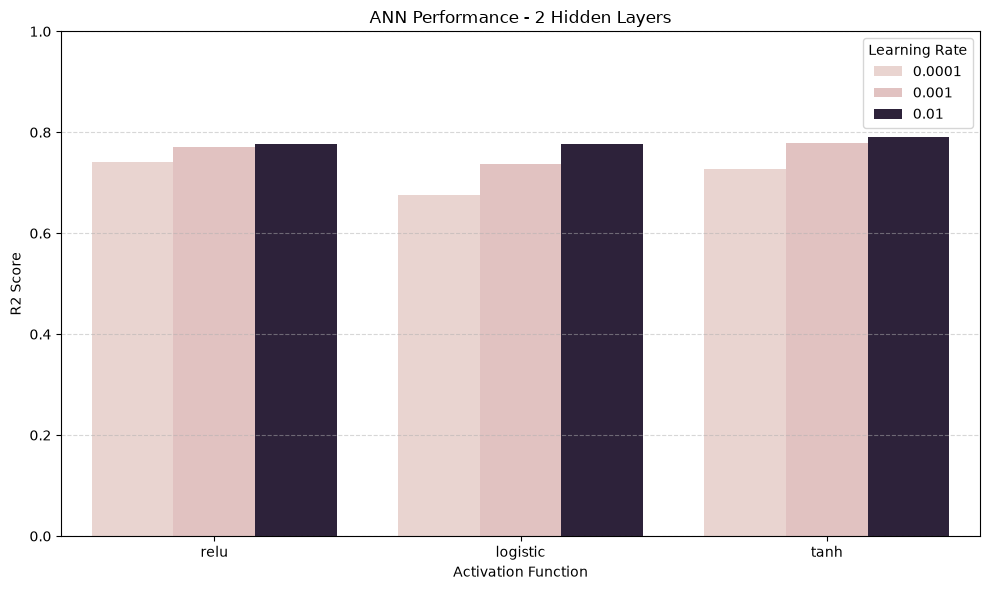

In [46]:
# Filter results for 2 hidden layers

results_2_layers = ann_results_df[
    ann_results_df["Hidden_Layers"] == 2
]

# Create grouped bar chart

plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_2_layers,
    x="Activation",
    y="R2",
    hue="Learning_Rate"
)

plt.title("ANN Performance - 2 Hidden Layers")
plt.xlabel("Activation Function")
plt.ylabel("R2 Score")
plt.ylim(0, 1)

plt.legend(title="Learning Rate")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

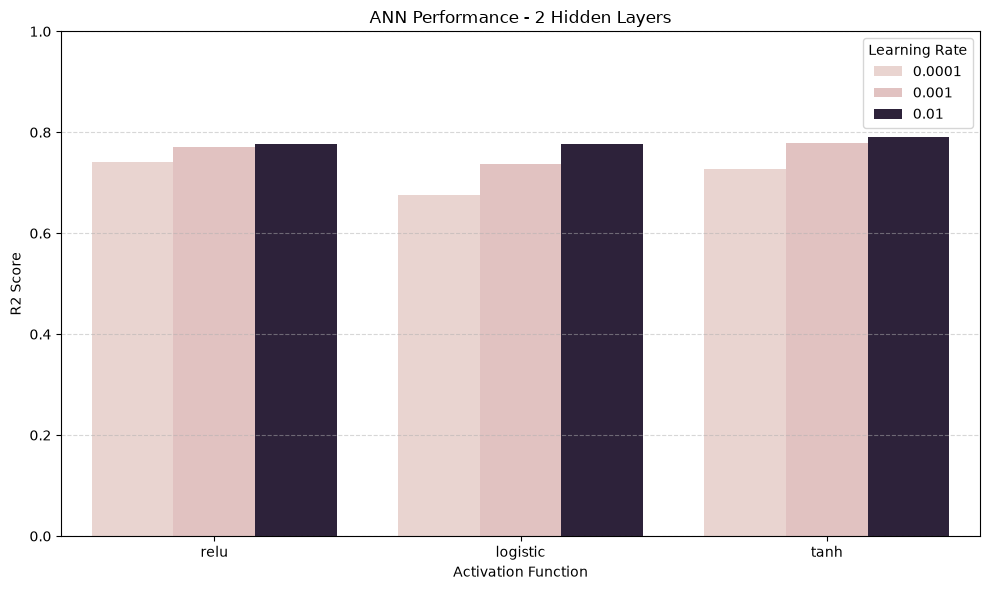

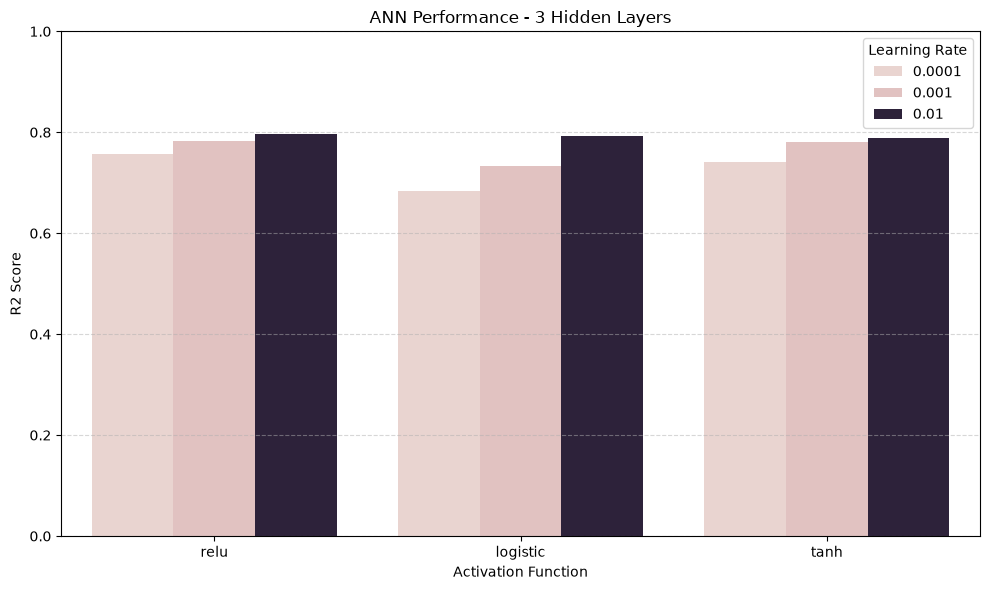

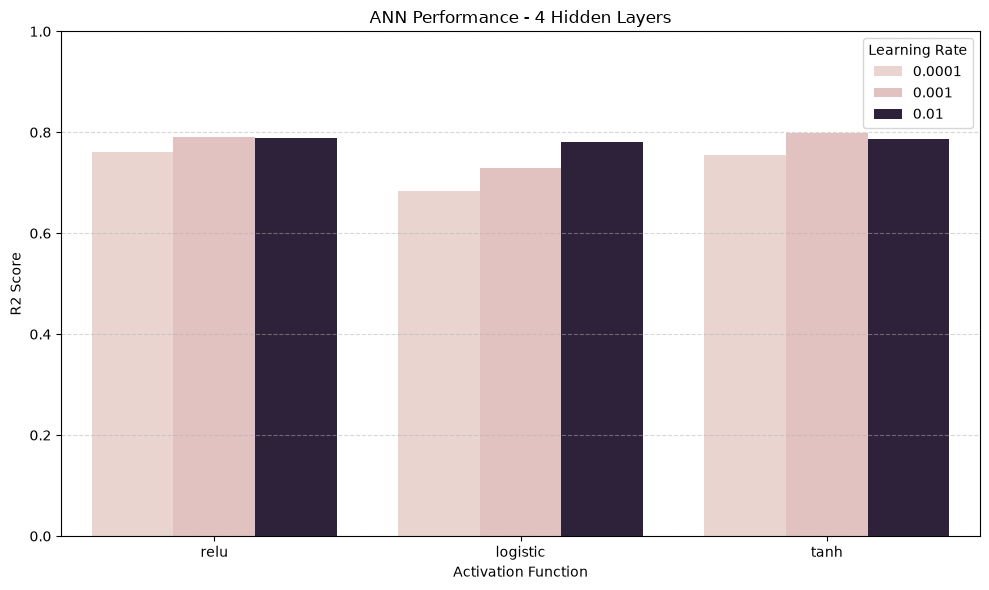

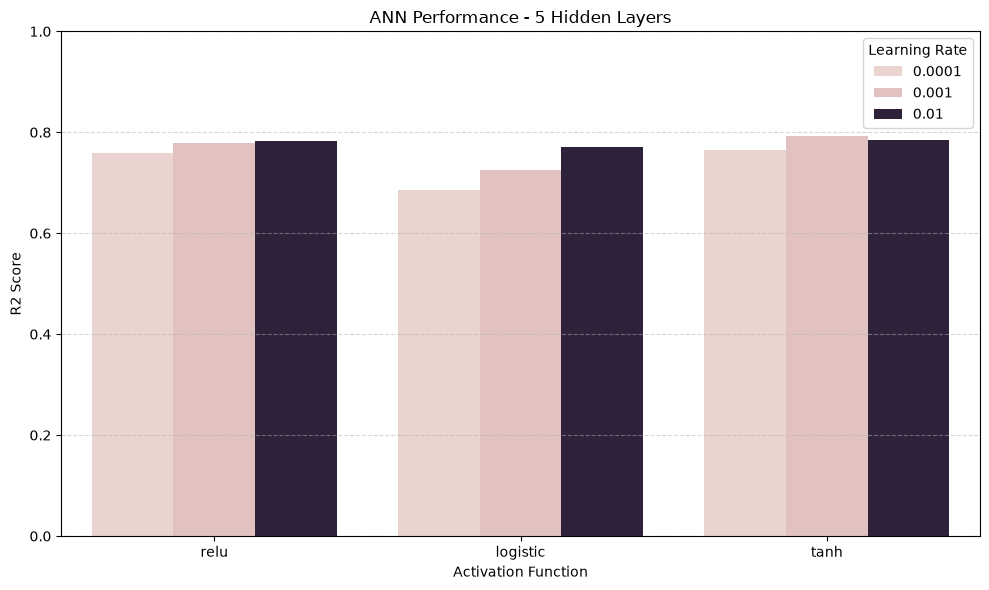

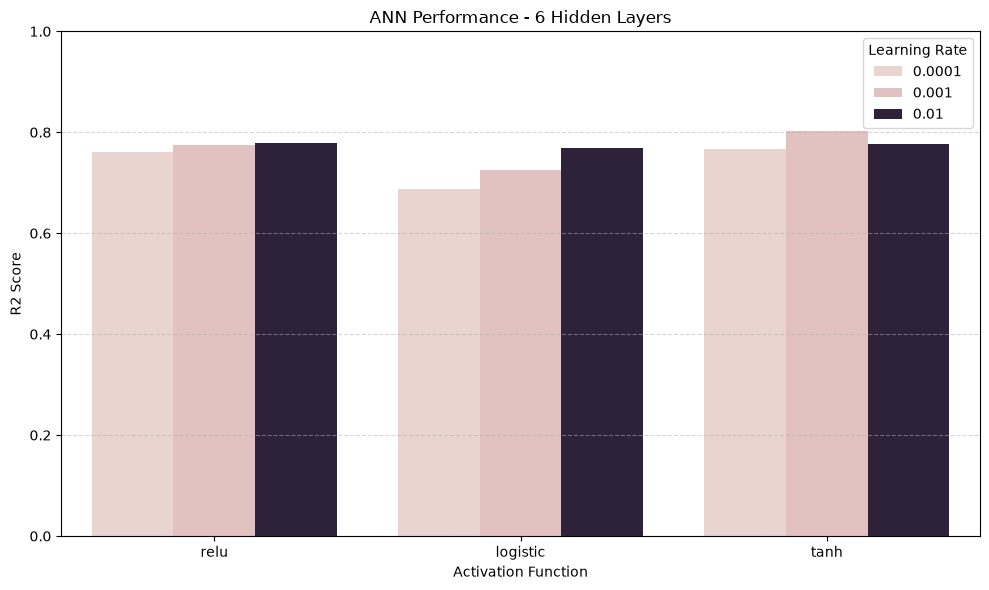

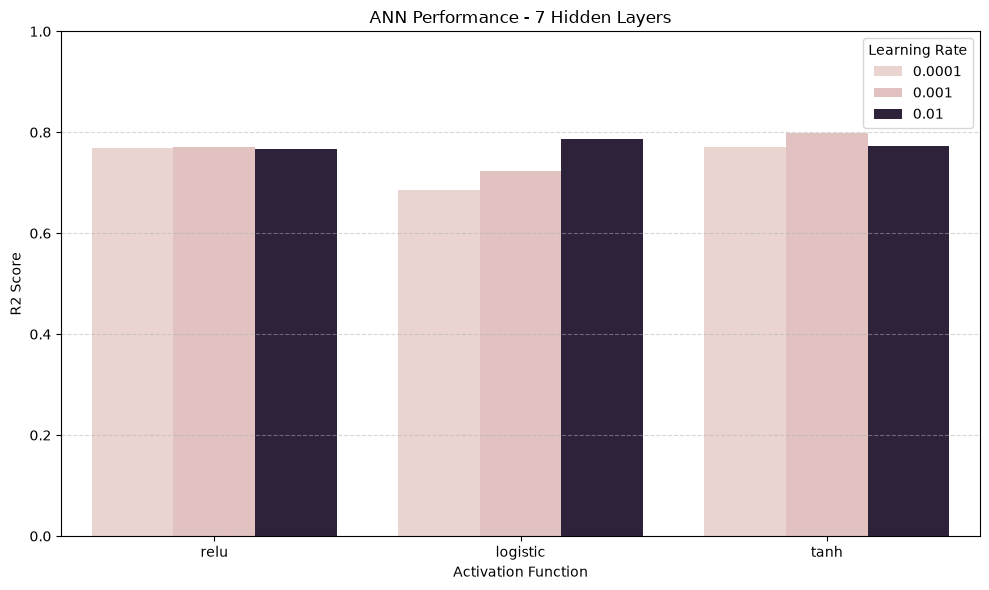

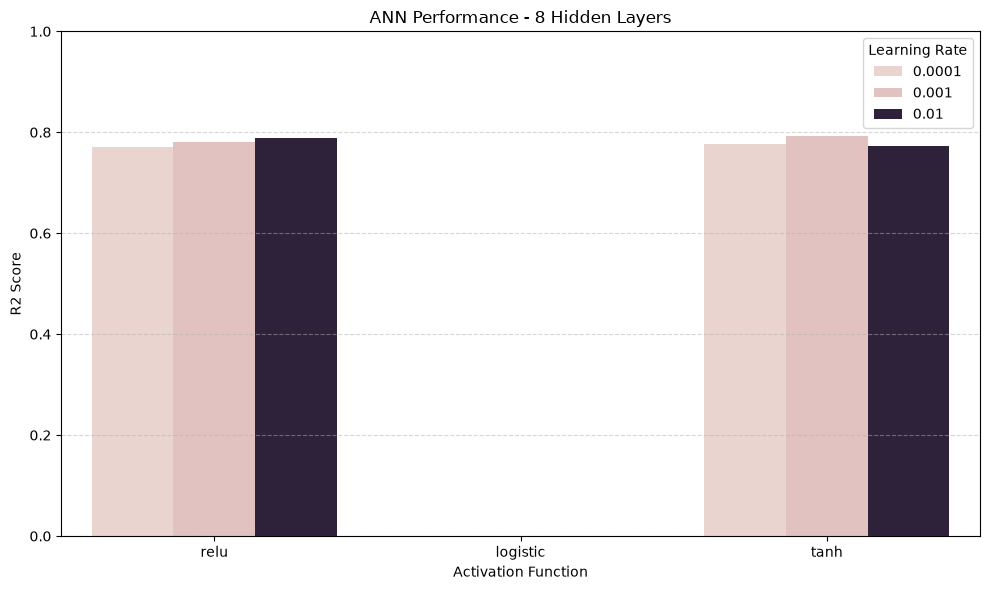

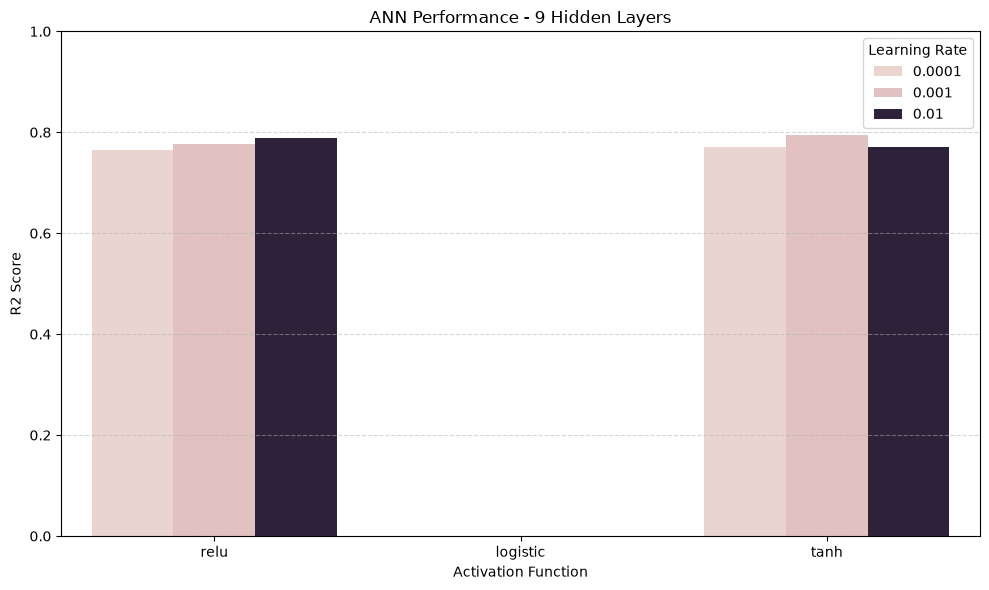

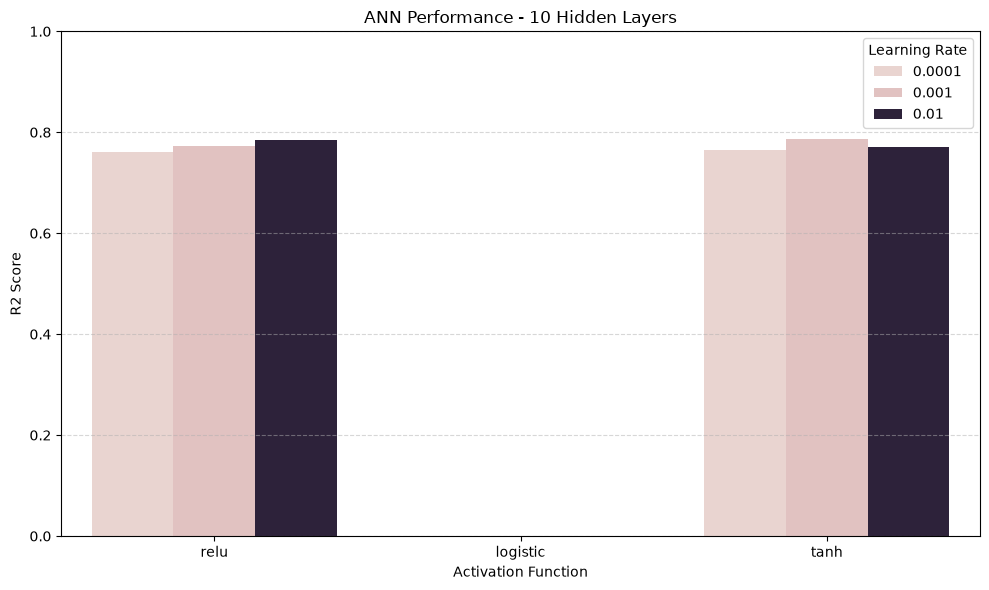

In [47]:
# Generate nine ANN comparison graphs

for layers in range(2, 11):

    results = ann_results_df[
        ann_results_df["Hidden_Layers"] == layers
    ]

    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=results,
        x="Activation",
        y="R2",
        hue="Learning_Rate"
    )

    plt.title(f"ANN Performance - {layers} Hidden Layers")
    plt.xlabel("Activation Function")
    plt.ylabel("R2 Score")
    plt.ylim(0, 1)

    plt.legend(title="Learning Rate")
    plt.grid(axis="y", linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.show()

In [48]:
import os

# Create figures folder if it does not exist
os.makedirs("../figures", exist_ok=True)

# Generate and save all nine graphs

for layers in range(2, 11):

    results = ann_results_df[
        ann_results_df["Hidden_Layers"] == layers
    ]

    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=results,
        x="Activation",
        y="R2",
        hue="Learning_Rate"
    )

    plt.title(f"ANN Performance - {layers} Hidden Layers")
    plt.xlabel("Activation Function")
    plt.ylabel("R2 Score")
    plt.ylim(0, 1)

    plt.legend(title="Learning Rate")
    plt.grid(axis="y", linestyle="--", alpha=0.5)

    plt.tight_layout()

    # Save graph
    plt.savefig(
        f"../figures/ANN_{layers}_Hidden_Layers.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

print("All nine graphs saved successfully!")

All nine graphs saved successfully!


In [49]:
# Create results folder if it does not exist

os.makedirs("../results", exist_ok=True)

# Save all 81 experiment results

ann_results_df.to_csv(
    "../results/ANN_Experiment_Results.csv",
    index=False
)

# Save the top 10 models

top_10_models.head(10).to_csv(
    "../results/ANN_Top_10_Models.csv",
    index=False
)

print("ANN results saved successfully!")
print("Total experiments saved:", len(ann_results_df))

ANN results saved successfully!
Total experiments saved: 81


In [50]:
# Create a comparison of all regression models

model_comparison = pd.DataFrame({
    "Model": [
        "Multiple Linear Regression",
        "KNN Regression (K=7)",
        "ANN - Initial Model",
        "ANN - Best Model"
    ],

    "R2": [
        0.613866,
        0.709497,
        0.770674,
        0.803074
    ],

    "MAE": [
        51810.48,
        41661.51,
        37653.92,
        33923.78
    ],

    "RMSE": [
        71133.17,
        61699.10,
        54818.84,
        50799.01
    ]
})

model_comparison

,Model,R2,MAE,RMSE
0,Multiple Linear Regression,0.613866,51810.48,71133.17
1,KNN Regression (K=7),0.709497,41661.51,61699.10
2,ANN - Initial Model,0.770674,37653.92,54818.84
3,ANN - Best Model,0.803074,33923.78,50799.01


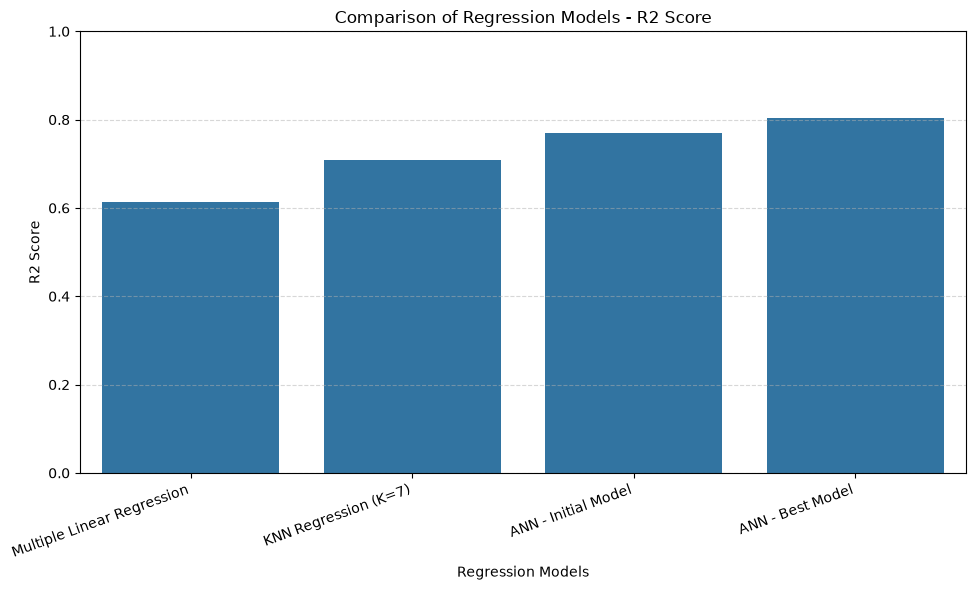

In [51]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="R2"
)

plt.title("Comparison of Regression Models - R2 Score")
plt.xlabel("Regression Models")
plt.ylabel("R2 Score")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("../figures/Model_Comparison_R2.png", dpi=300)
plt.show()

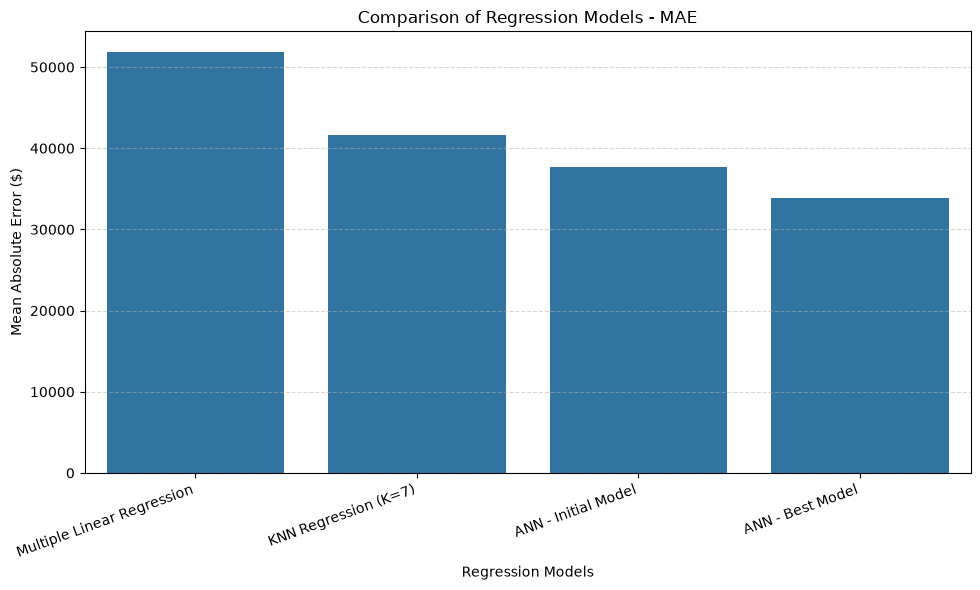

In [52]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="MAE"
)

plt.title("Comparison of Regression Models - MAE")
plt.xlabel("Regression Models")
plt.ylabel("Mean Absolute Error ($)")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("../figures/Model_Comparison_MAE.png", dpi=300)
plt.show()

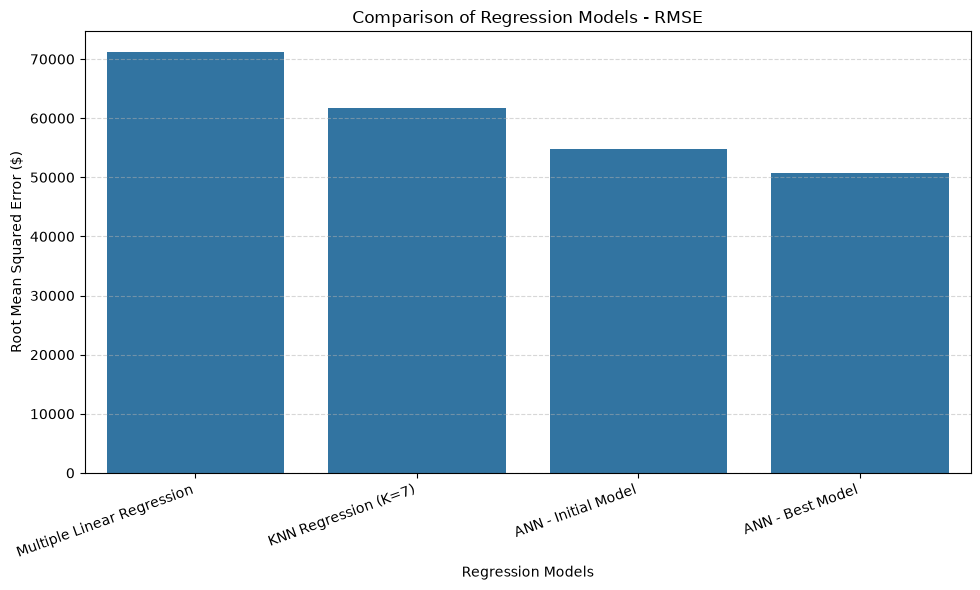

In [53]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="RMSE"
)

plt.title("Comparison of Regression Models - RMSE")
plt.xlabel("Regression Models")
plt.ylabel("Root Mean Squared Error ($)")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("../figures/Model_Comparison_RMSE.png", dpi=300)
plt.show()